In [202]:
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch_geometric.nn import GCNConv, GAE
import pandas as pd
import numpy as np
from torch.utils.data import DataLoader, TensorDataset
from sklearn.preprocessing import MinMaxScaler
from torch_geometric.utils import from_scipy_sparse_matrix
from torch_geometric.data import Data
import scipy.sparse as sp
import networkx as nx
import matplotlib.pyplot as plt
from torch.nn import BatchNorm1d
from sklearn.metrics import roc_auc_score, average_precision_score, precision_score, recall_score, f1_score
import torch
import torch.nn.functional as F
from torch_geometric.nn import GCNConv
from torch.nn import BatchNorm1d
from torch_geometric.utils import dropout_adj
import random
random.seed(42)
np.random.seed(42)
torch.manual_seed(42)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(42)

from sklearn.decomposition import NMF
from sklearn.preprocessing import StandardScaler


In [204]:


# ─── 1) GCN Encoder ─────────────────────────────────────────────────────────
# Functions
class GCNEncoder(torch.nn.Module):
    def __init__(self, in_channels, hidden_channels, out_channels, num_layers=3, dropout_rate=0.01, edge_dropout_rate=0.1):
        super(GCNEncoder, self).__init__()
        self.num_layers = num_layers
        self.dropout_rate = dropout_rate
        self.edge_dropout_rate = edge_dropout_rate
        
        # First layer: input to 2x hidden size
        self.convs = torch.nn.ModuleList()
        self.convs.append(GCNConv(in_channels, 2 * hidden_channels, cached=False))
        
        # Add intermediate layers
        for _ in range(num_layers - 2):
            self.convs.append(GCNConv(2 * hidden_channels, 2 * hidden_channels, cached=False))
        
        # Final layer: hidden size to output size
        self.convs.append(GCNConv(2 * hidden_channels, out_channels, cached=False))
    
        # Batch normalization layers for each convolution layer
        self.bns = torch.nn.ModuleList([BatchNorm1d(2 * hidden_channels, momentum=0.1) for _ in range(num_layers - 1)])

    
        # Dropout rate
        self.dropout = torch.nn.Dropout(p=dropout_rate)
        
        # Activation
        self.activation_hidden = torch.nn.ReLU  # For hidden layers
        self.activation_output = torch.nn.Sigmoid()  # For final layer


    
    def forward(self, x, edge_index):
        # Apply edge dropout
        #edge_index, _ = dropout_adj(edge_index, p=self.edge_dropout_rate, training=self.training)
        
        # First layer (without batch normalization)
        x = self.convs[0](x, edge_index)
        x = F.relu(x)
    
    # Intermediate layers with batch normalization and dropout
        for i in range(1, self.num_layers - 1):
            x_residual = x # For residual connection
            x = self.convs[i](x, edge_index)
            x = self.bns[i-1](x) # Apply batch normalization
            x = F.relu(x)
            x = self.dropout(x)
            
            # Add residual connection (skip connection)
            x = x + x_residual
    
        # Final layer (no activation or batch norm)
        x = self.convs[-1](x, edge_index)
        x = F.relu(x)

        return x

# ─── 2) Normalized Laplacian helper ─────────────────────────────────────────
def normalize_adj(adj):
    """Compute the normalized Laplacian."""
    adj = sp.coo_matrix(adj)
    rowsum = np.array(adj.sum(1)).flatten()
    d_inv_sqrt = np.power(rowsum + 1e-5, -0.5)
    d_inv_sqrt[np.isinf(d_inv_sqrt)] = 0.0
    d_mat_inv_sqrt = sp.diags(d_inv_sqrt)
    identity = sp.eye(adj.shape[0])  # Identity matrix of the same size as adj
    laplacian = identity - d_mat_inv_sqrt.dot(adj).dot(d_mat_inv_sqrt)  # Normalized Laplacian
    return laplacian.tocoo()


# ─── 3) Single‐view GAE run ─────────────────────────────────────────────────
def apply_gae_to_adjacency(adj_matrix, node_features, embedding_dim=8, epochs=200, dropout_rate=0.01, edge_dropout_rate=0.8,weight_decay=1e-4):
    
    # Convert adjacency matrix to sparse format
    adj_sparse = sp.csr_matrix(adj_matrix)
    
    # Normalize the adjacency matrix
    adj_normalized = normalize_adj(adj_sparse + sp.eye(adj_sparse.shape[0]))
    
    # Get edge_index and edge_weight
    edge_index, edge_weight = from_scipy_sparse_matrix(adj_normalized)
    
    # Create data object
    x = torch.tensor(node_features, dtype=torch.float)
    data = Data(x=x, edge_index=edge_index)

    # Define the GCNEncoder as the encoder for the GAE model
    encoder = GCNEncoder(in_channels=x.shape[1], hidden_channels=embedding_dim, out_channels=embedding_dim, dropout_rate=dropout_rate, edge_dropout_rate = edge_dropout_rate)

    # Instantiate the GAE model by passing the encoder
    model = GAE(encoder)

    # Training settings
    device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
    model = model.to(device)
    data = data.to(device)
    optimizer = torch.optim.Adam(model.parameters(), lr=0.01, weight_decay=weight_decay)  # Applying weight decay le = 0.05

    # Training loop
    model.train()
    for epoch in range(1, epochs + 1):
        optimizer.zero_grad()
        z = model.encode(data.x, data.edge_index)
        loss = model.recon_loss(z, data.edge_index)
        loss.backward()
        optimizer.step()

    # After training, reconstruct adjacency matrix
    model.eval()
    with torch.no_grad():
        z = model.encode(data.x, data.edge_index)
        adj_reconstructed = model.decoder.forward_all(z).cpu().numpy()
        
    return adj_reconstructed


# ─── 4) Running GCN-GAE multiple times  ────────────────────────────────────────────────
def run_gae_multiple_thresholds(data, ground_truth, algorithms, thresholds, num_iterations=30):
    
    # Number of genes
    num_genes = data.shape[0]

    # Helper variables
    all_results = {}
    iteration_sums = {}

    # Running the loops
    for threshold in thresholds:
        print(f"Running for threshold: {threshold}")
        
        # Create a dictionary to store the results for each algorithm and threshold
        all_results[f'threshold_{threshold}'] = {}
        iteration_sums[f'threshold_{threshold}'] = {}

        # Initialize the iteration sum matrices for each threshold
        for iter_num in range(num_iterations):
            iteration_sums[f'threshold_{threshold}'][f'iter{iter_num + 1}_GCN_sum'] = np.zeros((num_genes, num_genes))

        for alg in algorithms:
            print(f"Running GAE for algorithm: {alg} with threshold: {threshold}")
            alg_columns = [col for col in data.columns if col.startswith(alg + '.')]
            alg_matrix = data[alg_columns].values

            # For each algorithm, create a list to store multiple runs
            all_results[f'threshold_{threshold}'][alg] = []

            for iteration in range(num_iterations):
                print(f"Iteration {iteration + 1}/{num_iterations} for algorithm: {alg}")
                
                # Apply GAE to the adjacency matrix of the algorithm
                adj_reconstructed = apply_gae_to_adjacency(alg_matrix, node_features)
                
                # Binarize the reconstructed adjacency matrix using the current threshold
                adj_binary = (adj_reconstructed > threshold).astype(int)

                # Store the binary adjacency matrix for this run
                all_results[f'threshold_{threshold}'][alg].append(adj_binary)

                # Add the binary matrix to the sum for this iteration and threshold
                iteration_sums[f'threshold_{threshold}'][f'iter{iteration + 1}_GCN_sum'] += adj_binary

    return all_results, iteration_sums


# ─── 5) Voting-system  ──────────────────────────────────────────────── 
def collapse_iterations(mats, vote_threshold=None, top_k=None):
    """
    Collapses multiple binary (N×N) matrices into one using either:
    - Majority voting (default)
    - Top-K highest scoring edges (if top_k is provided)
    
    Parameters:
    - mats: list of (N, N) binary numpy arrays
    - vote_threshold: for voting-based binarization
    - top_k: if given, applies top-K filtering instead of voting
    
    Returns:
    - (N, N) binary adjacency matrix
    """
    stack = np.stack(mats, axis=0)  # shape (num_iters, N, N)
    summed = stack.sum(axis=0)      # edge vote counts
    
    if top_k is not None:
        # Use top-K edge binarization
        n = summed.shape[0]
        iu = np.triu_indices(n, k=1)
        scores = summed[iu]

        top_k_indices = np.argpartition(scores, -top_k)[-top_k:]
        binary_upper = np.zeros_like(scores)
        binary_upper[top_k_indices] = 1

        bin_adj = np.zeros((n, n))
        bin_adj[iu] = binary_upper
        bin_adj = bin_adj + bin_adj.T  # symmetric
        return bin_adj.astype(int)

    # Default: majority voting
    if vote_threshold is None:
        vote_threshold = int(np.floor(len(mats) / 2)) + 1
    return (summed >= vote_threshold).astype(int)


# ─── 6) Removing based on Jaccard Similarity  ──────────────────────────────────────────────── 
def jaccard_similarity(mat1, mat2):
    mat1_flat = mat1.flatten()
    mat2_flat = mat2.flatten()
    intersection = np.logical_and(mat1_flat, mat2_flat).sum()
    union = np.logical_or(mat1_flat, mat2_flat).sum()
    return intersection / union if union != 0 else 0

def compute_algorithm_jaccard_matrix(binarized_dict):
    algs = list(binarized_dict.keys())
    n = len(algs)
    sim_matrix = np.zeros((n, n))
    for i in range(n):
        for j in range(n):
            sim_matrix[i, j] = jaccard_similarity(binarized_dict[algs[i]], binarized_dict[algs[j]])
    return algs, sim_matrix

def filter_low_similarity_algorithms(
    binarized_dict,
    remove_k: int = None,
    bottom_percent: float = None
):
    """
    Remove the `remove_k` algorithms with lowest average Jaccard similarity,
    or, if remove_k is None, remove the bottom bottom_percent fraction.
    """
    algs, sim_matrix = compute_algorithm_jaccard_matrix(binarized_dict)
    avg_sim = sim_matrix.mean(axis=1)
    n = len(algs)

    # decide how many to drop
    if remove_k is None:
        if bottom_percent is None:
            raise ValueError("Must specify either remove_k or bottom_percent")
        remove_k = int(np.floor(n * bottom_percent))

    # get the indices of the lowest‐sim algorithms
    remove_indices = np.argsort(avg_sim)[:remove_k]
    remove_set = {algs[i] for i in remove_indices}

    # filter them out
    return {alg: mat for alg, mat in binarized_dict.items() if alg not in remove_set}


# ─── 7) Applying NMF to 17 algorithm ────────────────────────────────────────────────────────────── 
def fuse_with_joint_nmf_from_filtered(
    all_results,
    threshold,
    rank=20,
    num_genes=100,
    bottom_percent=0.15
):
    """
    all_results: dict of the form
       { 'threshold_<T>': { alg1: M1, alg2: M2, … } }
    where each Mi is EITHER
      - a list of binary (N×N) matrices, or
      - a single consensus binary (N×N) matrix.

    This function will:
      1) For each alg, if you passed a list → collapse it,
         else assume it's already the (N×N) matrix.
      2) Filter out the bottom‐percent least‐similar algorithms.
      3) Run joint NMF on the remaining binary mats.
    """
    import numpy as np
    from sklearn.decomposition import NMF

    # 1) Build consensus dict of pure (N×N) numpy arrays
    consensus = {}
    for alg, mats in all_results[f'threshold_{threshold}'].items():
        if isinstance(mats, list):
            # majority‐vote collapse
            vt = int(np.floor(len(mats) / 2)) + 1
            consensus[alg] = collapse_iterations(mats, vote_threshold=vt)
        else:
            # assume it's already the NxN matrix
            consensus[alg] = mats.copy()

    # 2) Filter out the bottom X% or X by Jaccard similarity
    filtered = filter_low_similarity_algorithms(consensus, remove_k=0)

    # 3) Stack & run NMF
    all_flattened = []
    for alg, mat in filtered.items():
        assert mat.shape == (num_genes, num_genes), f"{alg} shape is invalid: {mat.shape}"
        all_flattened.append(mat.flatten())

    V = np.array(all_flattened).T   # shape: (N², #algs_after_filter)
    nmf = NMF(n_components=rank, init='random', random_state=42, max_iter=1000)
    W = nmf.fit_transform(V)
    H = nmf.components_

    # mean‐over‐algorithms fusion
    V_rec = (W @ H).mean(axis=1)
    fused = V_rec.reshape((num_genes, num_genes))
    # normalize back to [0,1]
    fused = (fused - fused.min()) / (fused.max() - fused.min())
    return fused


In [206]:
##############################################################################################################
######## MORE TYPES OF COMBINATION
##############################################################################################################

#### Entropy‑weighted fusion (cheap, no tuning)
## **Idea **Edges that all algorithms agree on (low entropy) get larger weights than edges with wild disagreement.
def entropy_weight_fusion(soft_scores_dict):
    """
    soft_scores_dict : {alg : (N,N) float} – averaged GAE recon for each algorithm
    returns fused_adj : (N,N) float
    """
    algs   = list(soft_scores_dict)
    cube   = np.stack([soft_scores_dict[a] for a in algs], axis=-1)          # (N,N,A)
    p      = cube / (cube.sum(-1, keepdims=True) + 1e-9)                    # normalise
    entr   = -(p * np.log(p + 1e-9)).sum(-1)                                # (N,N)
    w_edge = 1 / (entr + 1e-9)                                              # low entropy → big weight
    fused_adj = (cube * w_edge[..., None]).sum(-1) / w_edge.sum(-1)         # weighted mean
    return fused_adj

#fused_adj = entropy_weight_fusion(soft_scores)


### Here is the GAE:


def run_gae_multiple_thresholds(data, ground_truth, algorithms, thresholds, num_iterations=30):
    
    # Number of genes
    num_genes = data.shape[0]

    # Helper variables
    all_results = {}
    iteration_sums = {}

    # Running the loops
    for threshold in thresholds:
        print(f"Running for threshold: {threshold}")
        
        # Create a dictionary to store the results for each algorithm and threshold
        all_results[f'threshold_{threshold}'] = {}
        iteration_sums[f'threshold_{threshold}'] = {}

        # Initialize the iteration sum matrices for each threshold
        for iter_num in range(num_iterations):
            iteration_sums[f'threshold_{threshold}'][f'iter{iter_num + 1}_GCN_sum'] = np.zeros((num_genes, num_genes))

        for alg in algorithms:
            print(f"Running GAE for algorithm: {alg} with threshold: {threshold}")
            alg_columns = [col for col in data.columns if col.startswith(alg + '.')]
            alg_matrix = data[alg_columns].values

            # For each algorithm, create a list to store multiple runs
            all_results[f'threshold_{threshold}'][alg] = []

            for iteration in range(num_iterations):
                print(f"Iteration {iteration + 1}/{num_iterations} for algorithm: {alg}")
                
                # Apply GAE to the adjacency matrix of the algorithm
                adj_reconstructed = apply_gae_to_adjacency(alg_matrix, node_features)
                
                # Binarize the reconstructed adjacency matrix using the current threshold
                adj_binary = (adj_reconstructed > threshold).astype(int)

                # Store the binary adjacency matrix for this run
                all_results[f'threshold_{threshold}'][alg].append(adj_binary)

                # Add the binary matrix to the sum for this iteration and threshold
                iteration_sums[f'threshold_{threshold}'][f'iter{iteration + 1}_GCN_sum'] += adj_binary
        
    # Compute the average soft score matrix per algorithm
    avg_soft = np.mean(all_results[f'threshold_{threshold}'][alg], axis=0)
    if f"soft_scores_{threshold}" not in all_results:
        all_results[f"soft_scores_{threshold}"] = {}
    all_results[f"soft_scores_{threshold}"][alg] = avg_soft

    return all_results, iteration_sums
#### Similarity‑Network Fusion (SNF) – the “graph diffusion” classic
###Reference Wang et al., Nat. Methods 2014.

## Build Aᵢ = your per‑algorithm continuous matrix (we already have that).

## Convert each Aᵢ into a K‑NN similarity graph Sᵢ (K≈20).

## Iterate Sᵢ ← P × (average of others) for ~20 steps (P = row‑normalised).

## Average the final Sᵢ’s → fused_adj.

# from snf import compute

#fused_adj = compute(list(soft_scores.values()), K=20, t=20)


#### Top‑K rank aggregation instead of a hard cut‑off
## Your current voting collapses “edge present ≥VOTE_THRESH”.
## Try ranking each algorithm’s edges by score, keep top‑K edges per algorithm, then vote across algorithms.

def rank_vote(soft_dict, K=300, vote=3):
    """
    K    : keep top K scoring edges per algorithm
    vote : how many algorithms must nominate the edge
    """
    N   = next(iter(soft_dict.values())).shape[0]
    bag = np.zeros((N,N), dtype=int)
    for A in soft_dict.values():
        iu   = np.triu_indices(N,1)
        topK = np.argsort(A[iu])[-K:]              # indices of largest K
        rows = iu[0][topK]; cols = iu[1][topK]
        bag[rows, cols] += 1
        bag[cols, rows] += 1                       # make symmetric
    return (bag >= vote).astype(int)

# Call it in place of collapse_iterations.



#### Graph‑modularity maximisation (no labels, still an objective)
## If the biology you’re modelling expects modules / communities, maximise modularity Q while fusing:

## Find weights w such that the fused graph’s Newman–Girvan modularity Q is maximal.

## Because Q is computable with no ground truth, you can feed it to any optimiser (PSO / GA) to choose weights. Replace the AUPR objective I showed earlier with:

import networkx as nx

def modularity_objective(w):
    w = np.clip(w,0,1); w /= w.sum()
    fused = (score_cube @ w).squeeze()     # (N,N)
    G     = nx.from_numpy_array(fused)
    import community  # python‑louvain
    part  = community.best_partition(G, weight='weight')
    Q     = community.modularity(part, G, weight='weight')
    return -Q    # maximise → minimise negative


# The optimiser still gives you w_best, and you fuse as before.





In [208]:
if __name__ == "__main__":
    import numpy as np, pandas as pd

    # ─────────── 0) configuration ─────────────────────
    DATA_PATH      = "/Users/nirwantandukar/input_data/Database.DREAM4/NORMALIZED_EXP/normalized_weight_matrix_all_GRN_100_01_0.2filter.csv"
    GROUND_TRUTH   = "/Users/nirwantandukar/input_data/Database.DREAM4/GS/dream4_100_01_gs.csv"
    THRESHOLD      = 0.6    # binarization threshold for each GAE run
    NUM_ITERS      = 10     # how many GAE runs per algorithm
    #VOTE_THRESH    = NUM_ITERS // 2  # majority vote
    VOTE_THRESH    = 8
    NMF_RANK       = 20
    FINAL_CUTOFF   = 0.4    # threshold fused_adj → fused_bin
    

    # ─────────── 1) load data ─────────────────────────
    df  = pd.read_csv(DATA_PATH, index_col=0)
    gt  = pd.read_csv(GROUND_TRUTH, index_col=0)
    algos = sorted({c.split('.')[0] for c in df.columns})
    N = df.shape[0]
    num_genes = df.shape[0]
    # Node features (identity matrix)
    node_features = np.identity(num_genes)

    # Node features (gene expression)
    expr_df = pd.read_csv("/Users/nirwantandukar/input_data/Database.DREAM4/EXP/dream4_100_01_exp.csv", index_col=0)
    scaler = StandardScaler()
    X_scaled = scaler.fit_transform(expr_df.values)  # shape: (num_genes, num_conditions)
    node_features = X_scaled

    # ─────────── 2) multi‐iteration GAE ───────────────
    all_results, iteration_sums = run_gae_multiple_thresholds(
        data           = df,
        ground_truth   = gt,
        algorithms     = algos,
        thresholds     = [THRESHOLD],
        num_iterations = NUM_ITERS
    )

    # ─────────── 3) collapse per‐algorithm runs ────────
    consensus_per_alg = {}
    for alg, runs in all_results[f"threshold_{THRESHOLD}"].items():
        consensus_per_alg[alg] = collapse_iterations(runs, top_k = 150)

    # wrap into the same dict structure
    collapsed_results = {f"threshold_{THRESHOLD}": consensus_per_alg}
    
    # ─────────── 4) fuse across algorithms with NMF ────
    fused_adj = fuse_with_joint_nmf_from_filtered(
        all_results=collapsed_results,
        threshold=THRESHOLD,
        rank=NMF_RANK,
        num_genes=N,
        bottom_percent=0.10
    )
    
    # Extract soft score matrices
    #soft_scores = all_results[f"soft_scores_{THRESHOLD}"]

    # Fuse them using entropy-based weights
    #fused_adj = entropy_weight_fusion(soft_scores)
    #fused_adj = (fused_adj - fused_adj.min()) / (fused_adj.max() - fused_adj.min() + 1e-10)


    # Binarize the fused matrix
    #fused_bin = (fused_adj >= FINAL_CUTOFF).astype(int)
    #print(f"Edges in fused: {fused_bin.sum()//2}")

    

    # ─────────── 5) final binarization ────────────────
    #fused_bin = (fused_adj >= FINAL_CUTOFF).astype(int)
    #print(f"Edges in fused: {fused_bin.sum()//2}")


Running for threshold: 0.6
Running GAE for algorithm: GRN_ARACNE with threshold: 0.6
Iteration 1/10 for algorithm: GRN_ARACNE
Iteration 2/10 for algorithm: GRN_ARACNE
Iteration 3/10 for algorithm: GRN_ARACNE
Iteration 4/10 for algorithm: GRN_ARACNE
Iteration 5/10 for algorithm: GRN_ARACNE
Iteration 6/10 for algorithm: GRN_ARACNE
Iteration 7/10 for algorithm: GRN_ARACNE
Iteration 8/10 for algorithm: GRN_ARACNE
Iteration 9/10 for algorithm: GRN_ARACNE
Iteration 10/10 for algorithm: GRN_ARACNE
Running GAE for algorithm: GRN_BC3NET with threshold: 0.6
Iteration 1/10 for algorithm: GRN_BC3NET
Iteration 2/10 for algorithm: GRN_BC3NET
Iteration 3/10 for algorithm: GRN_BC3NET
Iteration 4/10 for algorithm: GRN_BC3NET
Iteration 5/10 for algorithm: GRN_BC3NET
Iteration 6/10 for algorithm: GRN_BC3NET
Iteration 7/10 for algorithm: GRN_BC3NET
Iteration 8/10 for algorithm: GRN_BC3NET
Iteration 9/10 for algorithm: GRN_BC3NET
Iteration 10/10 for algorithm: GRN_BC3NET
Running GAE for algorithm: GRN_C3NE

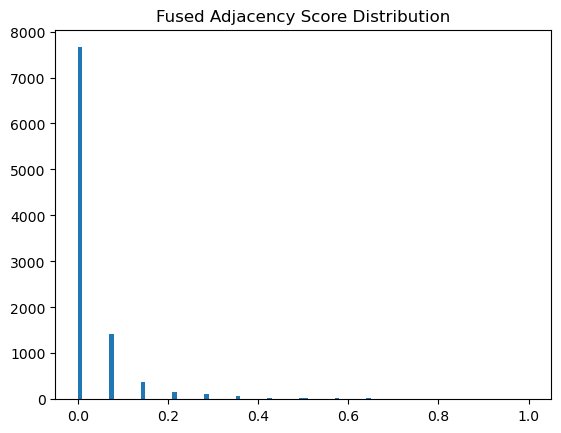

In [209]:

import matplotlib.pyplot as plt
plt.hist(fused_adj.flatten(), bins=100)
plt.title("Fused Adjacency Score Distribution")
plt.show()


In [210]:
# Load the data
data = pd.read_csv("/Users/nirwantandukar/input_data/Database.DREAM4/NORMALIZED_EXP/normalized_weight_matrix_all_GRN_100_01_0.2filter.csv", index_col=0)
#data = pd.read_csv("/Users/nirwantandukar/input_data/DREAM5/normalized_weight_matrix_DREAM5_net1_0.2filter.csv", index_col=0)
print(f"Loaded data with shape: {data.shape}")

# Get the list of algorithms
columns = data.columns
algorithms = sorted(set(col.split('.')[0] for col in columns))
print(f"Algorithms found: {algorithms}")

num_genes = data.shape[0]
gene_names = data.index.tolist()
print(f"Number of genes: {num_genes}")

# Function to extract nodes and edges from the binary matrix
def count_nodes_edges(final_matrix):
    # Count edges in the upper triangle (to avoid double counting for undirected graphs)
    num_edges = np.sum(np.triu(final_matrix, k=1))
    
    # Count nodes (genes with at least one edge, i.e., rows/columns with non-zero values)
    connected_nodes = np.sum(np.any(final_matrix, axis=1))  # Count rows with non-zero values
    num_nodes = connected_nodes
    
    return num_nodes, num_edges

# Function to extract gene interactions (edges) from a binarized matrix
def extract_gene_interactions(final_matrix, gene_names):
    edges = []
    num_genes = final_matrix.shape[0]

    # Loop through the upper triangle of the matrix to avoid duplicates (since it's undirected)
    for i in range(num_genes):
        for j in range(i + 1, num_genes):
            if final_matrix[i, j] == 1:  # Check if there's an interaction
                edges.append(f"{gene_names[i]}-{gene_names[j]}")
    
    return edges

# Count nodes and edges
num_nodes, num_edges = count_nodes_edges(fused_bin)
print(f"Nodes: {num_nodes}, Edges: {num_edges}")

# Get the edge list
nmf_edge_list = extract_gene_interactions(fused_bin, gene_names)
print(f"Sample edges: {nmf_edge_list[:5]}")

# Convert ground truth matrix to edge list
def convert_matrix_to_edge_list(matrix):
    edges = []
    for source in matrix.index:
        for target in matrix.columns:
            if matrix.at[source, target] == 1:
                edges.append((source, target))
    return edges

# Load known (ground truth) interactions
file_path = "/Users/nirwantandukar/input_data/Database.DREAM4/GS/dream4_100_01_gs.csv"
ground_truth = pd.read_csv(file_path, index_col=0)
print(f"Ground truth loaded with shape: {ground_truth.shape}")

# Get the ground truth edges
known_edges_set = set(convert_matrix_to_edge_list(ground_truth))
print(f"Number of known edges: {len(known_edges_set)}")

def convert_str_edges_to_tuples(edge_list):
    edge_tuples = set()
    for edge in edge_list:
        a, b = edge.split('-')
        # Add both (a, b) and (b, a) to ensure directionality doesn't affect matching
        edge_tuples.add((a, b))
        edge_tuples.add((b, a))
    return edge_tuples

predicted_edge_set = convert_str_edges_to_tuples(nmf_edge_list)

def symmetrize_edges(edge_set):
    symmetric_set = set()
    for a, b in edge_set:
        symmetric_set.add((a, b))
        symmetric_set.add((b, a))
    return symmetric_set

known_edges_symmetric = symmetrize_edges(known_edges_set)

#### AUPR and AUROC

from sklearn.metrics import roc_auc_score, average_precision_score

import numpy as np
from sklearn.metrics import roc_auc_score, average_precision_score

def compute_auroc_aupr_continuous(score_adj, ground_truth_df, gene_names):
    """
    Compute AUROC and AUPR on the *continuous* scores in score_adj,
    comparing against the binary ground truth in ground_truth_df.
    
    Parameters
    ----------
    score_adj : np.ndarray, shape (N,N)
        Your fused, continuous adjacency‐score matrix.
    ground_truth_df : pd.DataFrame, shape (N,N)
        Binary ground truth (0/1).
    gene_names : List[str], length N
        Row/column labels (in the same order as score_adj).
    
    Returns
    -------
    auroc : float
    aupr  : float
    """
    # 1) pull out the ground truth matrix in the right order
    gt_mat = ground_truth_df.loc[gene_names, gene_names].values.astype(int)
    
    # 2) flatten only the strict upper‐triangle
    iu      = np.triu_indices_from(gt_mat, k=1)
    y_true  = gt_mat[iu]
    y_score = score_adj[iu]
    
    # 3) compute
    auroc = roc_auc_score(y_true, y_score)
    aupr  = average_precision_score(y_true, y_score)
    
    print(f"Continuous AUROC: {auroc:.4f}")
    print(f"Continuous AUPR : {aupr:.4f}")
    return auroc, aupr


Loaded data with shape: (100, 1700)
Algorithms found: ['GRN_ARACNE', 'GRN_BC3NET', 'GRN_C3NET', 'GRN_CLR', 'GRN_GENIE3_ET', 'GRN_GENIE3_RF', 'GRN_GRENIST', 'GRN_GRNBOOST2', 'GRN_INFERELATOR', 'GRN_KBOOST', 'GRN_LEAP', 'GRN_MEOMI', 'GRN_MRNET', 'GRN_MRNETB', 'GRN_NONLINEARODES', 'GRN_PCIT', 'GRN_TIGRESS']
Number of genes: 100
Nodes: 92, Edges: 664
Sample edges: ['G1-G23', 'G1-G25', 'G1-G29', 'G1-G37', 'G1-G62']
Ground truth loaded with shape: (100, 100)
Number of known edges: 175


In [211]:
from sklearn.metrics import (
    roc_auc_score, average_precision_score,
    precision_score, recall_score, f1_score
)

def evaluate_all_metrics(fused_adj, ground_truth_df, gene_names, threshold=0.2):
    """
    fused_adj      : continuous matrix (N x N)
    ground_truth_df: DataFrame (gene x gene) binary
    gene_names     : List[str] → ordering
    threshold      : float, threshold on predicted scores
    """
    assert fused_adj.shape[0] == fused_adj.shape[1] == len(gene_names)
    
    # Align ground truth matrix
    gt_mat = ground_truth_df.loc[gene_names, gene_names].values.astype(int)
    
    # Get upper triangle only
    iu = np.triu_indices_from(fused_adj, k=1)
    preds_cont = fused_adj[iu]     # continuous predictions
    labels     = gt_mat[iu]        # ground truth binary

    # AUROC & AUPR
    auroc = roc_auc_score(labels, preds_cont)
    aupr  = average_precision_score(labels, preds_cont)

    # Thresholded metrics
    preds_bin = (preds_cont >= threshold).astype(int)
    precision = precision_score(labels, preds_bin, zero_division=0)
    recall    = recall_score(labels, preds_bin, zero_division=0)
    f1        = f1_score(labels, preds_bin, zero_division=0)

    return {
        'AUROC': round(auroc, 4),
        'AUPR':  round(aupr, 4),
        'Precision': round(precision, 4),
        'Recall':    round(recall, 4),
        'F1 Score':  round(f1, 4)
    }

metrics = evaluate_all_metrics(fused_adj, ground_truth, gene_names, threshold=0.2)
print(metrics)


{'AUROC': 0.7552, 'AUPR': 0.0703, 'Precision': 0.1083, 'Recall': 0.3297, 'F1 Score': 0.163}


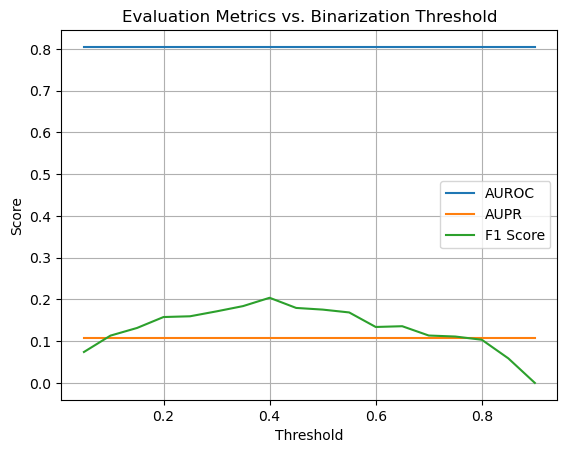

In [82]:
def sweep_thresholds(fused_adj, ground_truth_df, gene_names, thresholds):
    results = []
    for t in thresholds:
        metrics = evaluate_all_metrics(fused_adj, ground_truth_df, gene_names, threshold=t)
        metrics['Threshold'] = t
        results.append(metrics)
    
    df = pd.DataFrame(results)
    return df
thresholds_to_test = np.arange(0.05, 0.95, 0.05)
metrics_df = sweep_thresholds(fused_adj, ground_truth, gene_names, thresholds_to_test)
import matplotlib.pyplot as plt

# Plot AUROC, AUPR, F1
plt.figure()
for metric in ['AUROC', 'AUPR', 'F1 Score']:
    plt.plot(metrics_df['Threshold'], metrics_df[metric], label=metric)
plt.xlabel("Threshold")
plt.ylabel("Score")
plt.title("Evaluation Metrics vs. Binarization Threshold")
plt.legend()
plt.grid(True)
plt.show()


In [84]:
metrics = evaluate_all_metrics(fused_adj, ground_truth, gene_names, threshold=0.2)
print(metrics)

{'AUROC': 0.8047, 'AUPR': 0.1078, 'Precision': 0.0908, 'Recall': 0.6044, 'F1 Score': 0.1578}


In [86]:
from sklearn.metrics import roc_curve
import matplotlib.pyplot as plt
import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import (
    roc_curve, precision_recall_curve,
    roc_auc_score, average_precision_score,
    f1_score
)


def plot_roc_curve(fused_adj, ground_truth_df, gene_names):
    gt_mat = ground_truth_df.loc[gene_names, gene_names].values.astype(int)
    iu = np.triu_indices_from(fused_adj, k=1)
    y_true = gt_mat[iu]
    y_score = fused_adj[iu]

    fpr, tpr, _ = roc_curve(y_true, y_score)

    plt.figure(figsize=(6, 5))
    plt.plot(fpr, tpr, label=f'AUROC = {roc_auc_score(y_true, y_score):.4f}')
    plt.plot([0, 1], [0, 1], 'k--', label='Random (0.5)')
    plt.xlabel('False Positive Rate')
    plt.ylabel('True Positive Rate (Recall)')
    plt.title('ROC Curve')
    plt.legend()
    plt.grid(True)
    plt.tight_layout()
    plt.show()



In [88]:
from sklearn.metrics import precision_recall_curve

def plot_pr_curve(fused_adj, ground_truth_df, gene_names):
    gt_mat = ground_truth_df.loc[gene_names, gene_names].values.astype(int)
    iu = np.triu_indices_from(fused_adj, k=1)
    y_true = gt_mat[iu]
    y_score = fused_adj[iu]

    precision, recall, _ = precision_recall_curve(y_true, y_score)

    plt.figure(figsize=(6, 5))
    plt.plot(recall, precision, label=f'AUPR = {average_precision_score(y_true, y_score):.4f}')
    plt.xlabel('Recall')
    plt.ylabel('Precision')
    plt.title('Precision–Recall Curve')
    plt.legend()
    plt.grid(True)
    plt.tight_layout()
    plt.show()


In [90]:
def plot_f1_vs_threshold(fused_adj, ground_truth_df, gene_names):
    gt_mat = ground_truth_df.loc[gene_names, gene_names].values.astype(int)
    iu = np.triu_indices_from(fused_adj, k=1)
    y_true = gt_mat[iu]
    y_score = fused_adj[iu]

    thresholds = np.linspace(0, 1, 100)
    f1_scores = []
    for t in thresholds:
        y_pred = (y_score >= t).astype(int)
        f1 = f1_score(y_true, y_pred, zero_division=0)
        f1_scores.append(f1)

    plt.figure(figsize=(6, 5))
    plt.plot(thresholds, f1_scores)
    plt.xlabel('Threshold')
    plt.ylabel('F1 Score')
    plt.title('F1 Score vs. Threshold')
    plt.grid(True)
    plt.tight_layout()
    plt.show()


In [92]:
# Assuming you already have:
# fused_adj = your NMF fused output (100x100)
# ground_truth = pd.DataFrame with same index and columns as fused_adj

gene_names = list(ground_truth.index)
gt_mat = ground_truth.loc[gene_names, gene_names].values.astype(int)

# Upper triangle
iu = np.triu_indices_from(gt_mat, k=1)
y_true = gt_mat[iu]
y_score = fused_adj[iu]


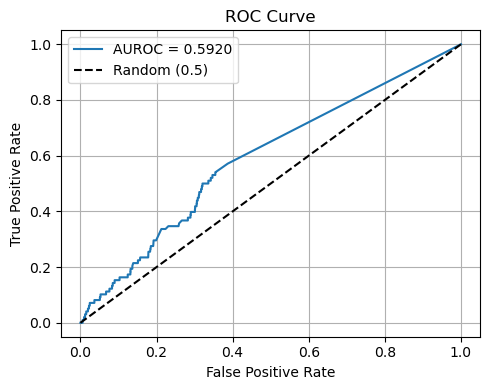

In [94]:
fpr, tpr, _ = roc_curve(y_true, y_score)
plt.figure(figsize=(5, 4))
plt.plot(fpr, tpr, label=f'AUROC = {roc_auc_score(y_true, y_score):.4f}')
plt.plot([0, 1], [0, 1], 'k--', label='Random (0.5)')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curve')
plt.grid(True)
plt.legend()
plt.tight_layout()
plt.show()


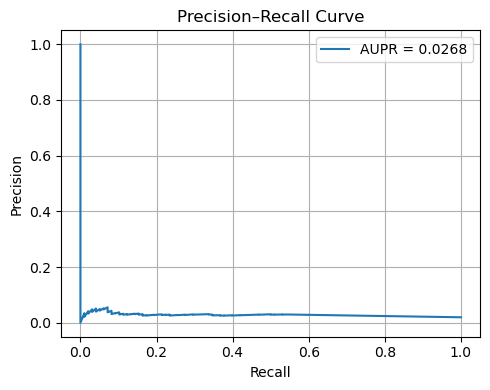

In [96]:
precision, recall, _ = precision_recall_curve(y_true, y_score)
plt.figure(figsize=(5, 4))
plt.plot(recall, precision, label=f'AUPR = {average_precision_score(y_true, y_score):.4f}')
plt.xlabel('Recall')
plt.ylabel('Precision')
plt.title('Precision–Recall Curve')
plt.grid(True)
plt.legend()
plt.tight_layout()
plt.show()


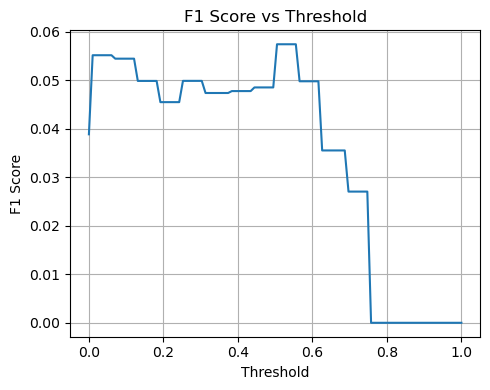

In [98]:
thresholds = np.linspace(0, 1, 100)
f1s = [f1_score(y_true, (y_score >= t).astype(int), zero_division=0) for t in thresholds]

plt.figure(figsize=(5, 4))
plt.plot(thresholds, f1s)
plt.xlabel('Threshold')
plt.ylabel('F1 Score')
plt.title('F1 Score vs Threshold')
plt.grid(True)
plt.tight_layout()
plt.show()
